In [1]:
import pandas as pd

df = pd.read_csv("results.csv")
print("rows loaded:", len(df))

df = df[df["error"].isna()].copy()          # keep only rows with no error text
df["D_over_F"] = df.distillate_kmolh / df.feed_flow_kmolh
df["reboiler_kW"] = df.reboiler_duty_cal_s * 4.184 / 1000

# mass balance check: benzene in = benzene out
F, z, D = df.feed_flow_kmolh, df.z_benzene, df.distillate_kmolh
df["bal_err"] = F*z - (D*df.xD_benzene + (F-D)*df.xB_benzene)
df = df[df.bal_err.abs() < 0.01]

print("rows kept:", len(df))
df[["feed_flow_kmolh","z_benzene","reflux_ratio","D_over_F",
    "reboiler_kW","xD_benzene"]].describe()

FileNotFoundError: [Errno 2] No such file or directory: 'results.csv'

In [2]:
from google.colab import files
uploaded = files.upload()

Saving results.csv to results.csv


import pandas as pd

df = pd.read_csv("results.csv")
print("rows loaded:", len(df))

df = df[df["error"].isna()].copy()          # keep only rows with no error text
df["D_over_F"] = df.distillate_kmolh / df.feed_flow_kmolh
df["reboiler_kW"] = df.reboiler_duty_cal_s * 4.184 / 1000

# mass balance check: benzene in = benzene out
F, z, D = df.feed_flow_kmolh, df.z_benzene, df.distillate_kmolh
df["bal_err"] = F*z - (D*df.xD_benzene + (F-D)*df.xB_benzene)
df = df[df.bal_err.abs() < 0.01]

print("rows kept:", len(df))
df[["feed_flow_kmolh","z_benzene","reflux_ratio","D_over_F",
    "reboiler_kW","xD_benzene"]].describe()

In [4]:
import pandas as pd

df = pd.read_csv("results.csv")
print("rows loaded:", len(df))

df = df[df["error"].isna()].copy()          # keep only rows with no error text
df["D_over_F"] = df.distillate_kmolh / df.feed_flow_kmolh
df["reboiler_kW"] = df.reboiler_duty_cal_s * 4.184 / 1000

# mass balance check: benzene in = benzene out
F, z, D = df.feed_flow_kmolh, df.z_benzene, df.distillate_kmolh
df["bal_err"] = F*z - (D*df.xD_benzene + (F-D)*df.xB_benzene)
df = df[df.bal_err.abs() < 0.01]

print("rows kept:", len(df))
df[["feed_flow_kmolh","z_benzene","reflux_ratio","D_over_F",
    "reboiler_kW","xD_benzene"]].describe()

rows loaded: 1000
rows kept: 1000


,feed_flow_kmolh,z_benzene,reflux_ratio,D_over_F,reboiler_kW,xD_benzene
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,100.000224,0.500000,2.749989,0.475001,1536.476361,0.949470
std,11.553223,0.057765,0.722076,0.072204,423.722114,0.075742
min,80.011553,0.400084,1.501629,0.350225,693.501628,0.687316
25%,90.022701,0.450065,2.125530,0.412566,1217.803913,0.920409
50%,99.997829,0.499981,2.750264,0.474993,1477.335637,0.994538
75%,110.001031,0.549872,3.375491,0.537382,1809.137831,0.998873
max,119.970284,0.599893,3.997968,0.599793,3051.932568,0.999674


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

features = ["feed_flow_kmolh", "z_benzene", "reflux_ratio", "D_over_F"]
X = df[features]

for target in ["reboiler_kW", "xD_benzene"]:
    y = df[target]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
    models = [("linear", LinearRegression()),
              ("random forest", RandomForestRegressor(n_estimators=300, random_state=42))]
    for name, m in models:
        m.fit(Xtr, ytr)
        p = m.predict(Xte)
        print(target, "|", name, "| R2 =", round(r2_score(yte, p), 4),
              "| MAE =", round(mean_absolute_error(yte, p), 4))

reboiler_kW | linear | R2 = 0.9808 | MAE = 43.0249
reboiler_kW | random forest | R2 = 0.9886 | MAE = 34.4128
xD_benzene | linear | R2 = 0.6699 | MAE = 0.0332
xD_benzene | random forest | R2 = 0.9938 | MAE = 0.0031


In [8]:
import numpy as np
from sklearn.model_selection import cross_val_score, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor

df["boilup"] = df.distillate_kmolh * (df.reflux_ratio + 1)
df["nines"] = -np.log10(1 - df.xD_benzene)

base = ["feed_flow_kmolh", "z_benzene", "reflux_ratio", "D_over_F"]
phys = base + ["boilup"]

models = {
    "linear": make_pipeline(StandardScaler(), LinearRegression()),
    "random forest": RandomForestRegressor(n_estimators=300, random_state=42),
    "grad boosting": GradientBoostingRegressor(random_state=42),
    "neural net": make_pipeline(StandardScaler(),
                                MLPRegressor(hidden_layer_sizes=(32, 32),
                                             max_iter=3000, random_state=42)),
}
cv = KFold(5, shuffle=True, random_state=42)

for target in ["reboiler_kW", "nines"]:
    for fname, cols in [("base", base), ("base+boilup", phys)]:
        for name, m in models.items():
            s = cross_val_score(m, df[cols], df[target], cv=cv, scoring="r2")
            print(f"{target:12s} | {fname:11s} | {name:13s} | R2 = {s.mean():.4f} +/- {s.std():.4f}")

reboiler_kW  | base        | linear        | R2 = 0.9767 +/- 0.0028
reboiler_kW  | base        | random forest | R2 = 0.9849 +/- 0.0025
reboiler_kW  | base        | grad boosting | R2 = 0.9895 +/- 0.0013


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (3000) reached and the optimization hasn't converged yet.
  warnings.warn(


reboiler_kW  | base        | neural net    | R2 = 0.9977 +/- 0.0018
reboiler_kW  | base+boilup | linear        | R2 = 0.9991 +/- 0.0001
reboiler_kW  | base+boilup | random forest | R2 = 0.9981 +/- 0.0006
reboiler_kW  | base+boilup | grad boosting | R2 = 0.9989 +/- 0.0005


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (3000) reached and the optimization hasn't converged yet.
  warnings.warn(


reboiler_kW  | base+boilup | neural net    | R2 = 0.9999 +/- 0.0001
nines        | base        | linear        | R2 = 0.7537 +/- 0.0173
nines        | base        | random forest | R2 = 0.9716 +/- 0.0112
nines        | base        | grad boosting | R2 = 0.9483 +/- 0.0088
nines        | base        | neural net    | R2 = 0.9831 +/- 0.0023
nines        | base+boilup | linear        | R2 = 0.7626 +/- 0.0166
nines        | base+boilup | random forest | R2 = 0.9699 +/- 0.0108
nines        | base+boilup | grad boosting | R2 = 0.9494 +/- 0.0081
nines        | base+boilup | neural net    | R2 = 0.9806 +/- 0.0033


In [10]:
import numpy as np
from sklearn.model_selection import cross_val_predict, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error

df["max_purity"] = np.minimum(1.0, df.z_benzene / df.D_over_F)
df["dz"] = df.D_over_F - df.z_benzene

base = ["feed_flow_kmolh", "z_benzene", "reflux_ratio", "D_over_F"]
sets = {"base": base, "base+max_purity+dz": base + ["max_purity", "dz"]}

nn = make_pipeline(StandardScaler(),
                   MLPRegressor(hidden_layer_sizes=(32, 32), solver="lbfgs",
                                max_iter=5000, random_state=42))
cv = KFold(5, shuffle=True, random_state=42)
near = df.xD_benzene >= 0.98          # the region that matters for optimization

for fname, cols in sets.items():
    pred_nines = cross_val_predict(nn, df[cols], df["nines"], cv=cv)
    pred_xD = 1 - 10 ** (-pred_nines)
    print(fname)
    print("   R2 on nines          :", round(r2_score(df.nines, pred_nines), 4))
    print("   MAE nines (all rows) :", round(mean_absolute_error(df.nines, pred_nines), 4))
    print("   MAE xD (all rows)    :", round(mean_absolute_error(df.xD_benzene, pred_xD), 5))
    print("   MAE xD (xD >= 0.98)  :", round(mean_absolute_error(df.xD_benzene[near], pred_xD[near]), 5))

base
   R2 on nines          : 0.9996
   MAE nines (all rows) : 0.0122
   MAE xD (all rows)    : 0.00116
   MAE xD (xD >= 0.98)  : 0.00011
base+max_purity+dz
   R2 on nines          : 0.9994
   MAE nines (all rows) : 0.0139
   MAE xD (all rows)    : 0.00139
   MAE xD (xD >= 0.98)  : 0.00014


train rows: 680 | test rows: 320

 reboiler_kW
  linear (base)          R2 =  0.9247 | MAE = 82.5529
  linear (+boilup)       R2 =  0.9980 | MAE = 13.2586
  random forest          R2 =  0.4595 | MAE = 242.1245
  grad boosting          R2 =  0.6351 | MAE = 191.3447
  neural net             R2 =  0.9958 | MAE = 17.4816
  neural net (+boilup)   R2 =  0.9999 | MAE = 2.2593

 nines
  linear (base)          R2 =  0.6907 | MAE = 0.5365
  linear (+boilup)       R2 =  0.7056 | MAE = 0.5159
  random forest          R2 =  0.9390 | MAE = 0.1914
  grad boosting          R2 =  0.9070 | MAE = 0.2491
  neural net             R2 =  0.9935 | MAE = 0.0478
  neural net (+boilup)   R2 =  0.9902 | MAE = 0.0504


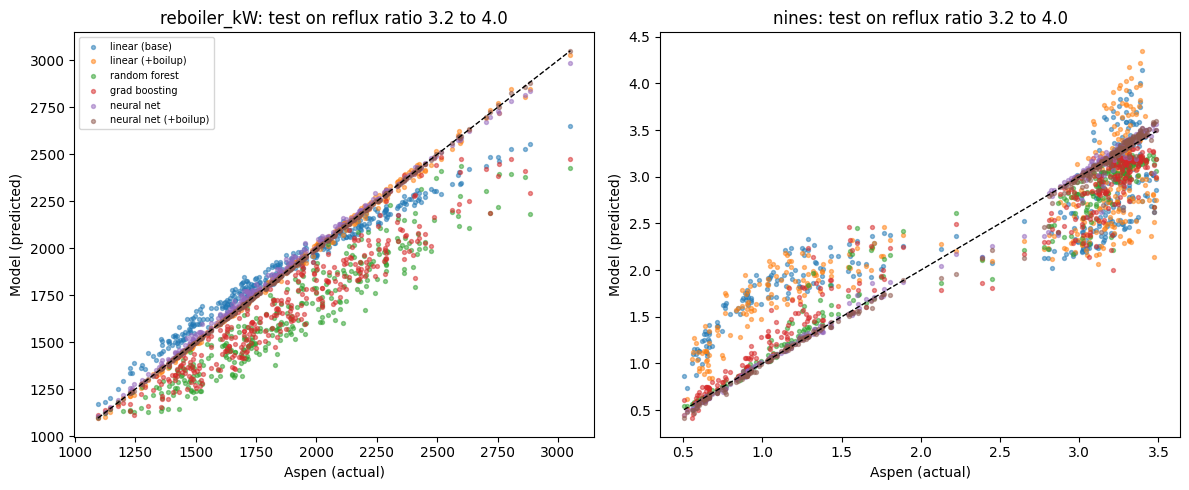

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_absolute_error

df["boilup"] = df.distillate_kmolh * (df.reflux_ratio + 1)
df["nines"] = -np.log10(1 - df.xD_benzene)

base = ["feed_flow_kmolh", "z_benzene", "reflux_ratio", "D_over_F"]
phys = base + ["boilup"]

train = df[df.reflux_ratio < 3.2]
test = df[df.reflux_ratio >= 3.2]
print("train rows:", len(train), "| test rows:", len(test))

def nn():
    return make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(32, 32), solver="lbfgs",
                                      max_iter=5000, random_state=42))

models = {
    "linear (base)":        (LinearRegression(), base),
    "linear (+boilup)":     (LinearRegression(), phys),
    "random forest":        (RandomForestRegressor(n_estimators=300, random_state=42), base),
    "grad boosting":        (GradientBoostingRegressor(random_state=42), base),
    "neural net":           (nn(), base),
    "neural net (+boilup)": (nn(), phys),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, target in zip(axes, ["reboiler_kW", "nines"]):
    print("\n", target)
    for name, (m, cols) in models.items():
        m.fit(train[cols], train[target])
        p = m.predict(test[cols])
        print(f"  {name:22s} R2 = {r2_score(test[target], p):7.4f} | MAE = {mean_absolute_error(test[target], p):.4f}")
        ax.scatter(test[target], p, s=8, alpha=0.5, label=name)
    lo, hi = test[target].min(), test[target].max()
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_xlabel("Aspen (actual)")
    ax.set_ylabel("Model (predicted)")
    ax.set_title(target + ": test on reflux ratio 3.2 to 4.0")
axes[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [14]:
import numpy as np
import pandas as pd
from scipy.optimize import minimize
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df["boilup"] = df.distillate_kmolh * (df.reflux_ratio + 1)
df["nines"] = -np.log10(1 - df.xD_benzene)
base = ["feed_flow_kmolh", "z_benzene", "reflux_ratio", "D_over_F"]
phys = base + ["boilup"]

def nn():
    return make_pipeline(StandardScaler(),
                         MLPRegressor(hidden_layer_sizes=(32, 32), solver="lbfgs",
                                      max_iter=5000, random_state=42))

duty_model = nn().fit(df[phys], df["reboiler_kW"])
nines_model = nn().fit(df[base], df["nines"])

F, z = 100.0, 0.5
PURITY_MIN, RECOVERY_MIN = 0.99, 0.95

def predict(R, D):
    row = pd.DataFrame([{"feed_flow_kmolh": F, "z_benzene": z, "reflux_ratio": R,
                         "D_over_F": D / F, "boilup": D * (R + 1)}])
    duty = duty_model.predict(row[phys])[0]
    xD = 1 - 10 ** (-nines_model.predict(row[base])[0])
    return duty, xD

# --- method 1: SLSQP optimizer from several starting points
def objective(x):
    return predict(*x)[0] / 1000
def purity_con(x):
    return (predict(*x)[1] - PURITY_MIN) * 100
def recovery_con(x):
    duty, xD = predict(*x)
    return (x[1] * xD / (F * z) - RECOVERY_MIN) * 100

bounds = [(1.5, 4.0), (35.0, 60.0)]
cons = [{"type": "ineq", "fun": purity_con}, {"type": "ineq", "fun": recovery_con}]
rng = np.random.default_rng(0)
results = []
for start in rng.uniform([1.5, 35], [4.0, 60], size=(10, 2)):
    r = minimize(objective, start, method="SLSQP", bounds=bounds, constraints=cons)
    duty, xD = predict(*r.x)
    ok = xD >= PURITY_MIN - 1e-4 and r.x[1] * xD / (F * z) >= RECOVERY_MIN - 1e-4
    results.append((duty, r.x[0], r.x[1], xD, ok))
    print(f"start {np.round(start,2)} -> R={r.x[0]:.3f} D={r.x[1]:.2f} duty={duty:.1f} kW xD={xD:.4f} feasible={ok}")

best = min((x for x in results if x[4]), key=lambda x: x[0])
print("\nOptimizer best: R=%.3f  D=%.2f  duty=%.1f kW  xD=%.4f" % (best[1], best[2], best[0], best[3]))

# --- method 2: brute-force grid, as an independent check
best_grid = None
for R in np.linspace(1.5, 4.0, 126):
    for D in np.linspace(35, 60, 126):
        duty, xD = predict(R, D)
        if xD >= PURITY_MIN and D * xD / (F * z) >= RECOVERY_MIN:
            if best_grid is None or duty < best_grid[0]:
                best_grid = (duty, R, D, xD)
print("Grid best:      R=%.3f  D=%.2f  duty=%.1f kW  xD=%.4f" % (best_grid[1], best_grid[2], best_grid[0], best_grid[3]))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)


start [ 3.09 41.74] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True
start [ 1.6  35.41] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True
start [ 3.53 57.82] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True
start [ 3.02 53.24] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True
start [ 2.86 58.38] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True
start [ 3.54 35.07] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True
start [ 3.64 35.84] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True
start [ 3.32 39.39] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True
start [ 3.66 48.54] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True
start [ 2.25 45.57] -> R=1.739 D=47.98 duty=1131.6 kW xD=0.9900 feasible=True

Optimizer best: R=1.739  D=47.98  duty=1131.6 kW  xD=0.9900
Grid best:      R=1.740  D=48.00  duty=1132.6 kW  xD=0.9900


R      duty(surr) duty(Aspen)  xD(surr)  xD(Aspen)
1.6       1075.7      1076.1   0.98522   0.98432
1.65      1095.8      1096.1   0.98720   0.98666
1.7       1116.0      1116.2   0.98887   0.98859
1.739     1131.7      1131.8   0.99001   0.98985
1.78      1148.3      1148.3   0.99108   0.99099
1.82      1164.4      1164.4   0.99201   0.99188
1.9       1196.7      1196.6   0.99360   0.99346


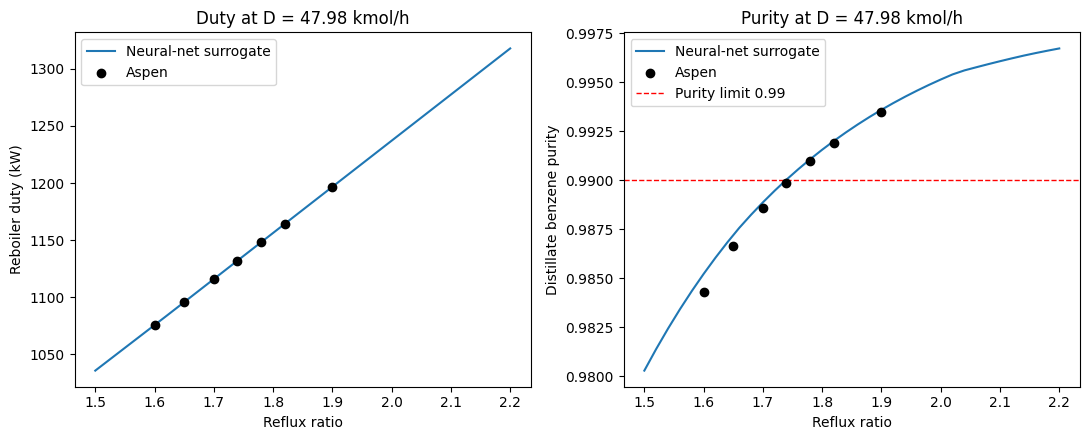

In [16]:
import os
import numpy as np
import matplotlib.pyplot as plt
os.makedirs("figures", exist_ok=True)

aspen_R    = [1.6, 1.65, 1.7, 1.739, 1.78, 1.82, 1.9]
aspen_duty = [1076.1, 1096.1, 1116.2, 1131.8, 1148.3, 1164.4, 1196.6]
aspen_xD   = [0.98432, 0.98666, 0.98859, 0.98985, 0.99099, 0.99188, 0.99346]

print("R      duty(surr) duty(Aspen)  xD(surr)  xD(Aspen)")
for R, da, xa in zip(aspen_R, aspen_duty, aspen_xD):
    ds, xs = predict(R, 47.98)
    print(f"{R:<6} {ds:9.1f} {da:11.1f}   {xs:.5f}   {xa:.5f}")

Rg = np.linspace(1.5, 2.2, 36)
sur = [predict(R, 47.98) for R in Rg]

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
ax[0].plot(Rg, [s[0] for s in sur], label="Neural-net surrogate")
ax[0].scatter(aspen_R, aspen_duty, color="k", zorder=3, label="Aspen")
ax[0].set_xlabel("Reflux ratio"); ax[0].set_ylabel("Reboiler duty (kW)")
ax[0].set_title("Duty at D = 47.98 kmol/h"); ax[0].legend()

ax[1].plot(Rg, [s[1] for s in sur], label="Neural-net surrogate")
ax[1].scatter(aspen_R, aspen_xD, color="k", zorder=3, label="Aspen")
ax[1].axhline(0.99, color="r", ls="--", lw=1, label="Purity limit 0.99")
ax[1].set_xlabel("Reflux ratio"); ax[1].set_ylabel("Distillate benzene purity")
ax[1].set_title("Purity at D = 47.98 kmol/h"); ax[1].legend()
plt.tight_layout()
plt.savefig("figures/fig_optimum_vs_aspen.png", dpi=200)
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  self.n_iter_ = _check_optimize_result("lbfgs", opt_res, self.max_iter)
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:546: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS R

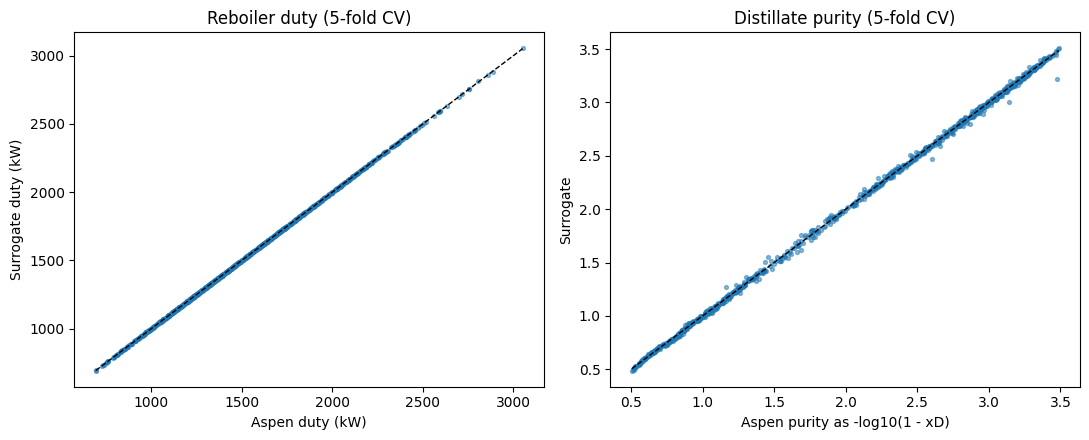

In [18]:
from sklearn.model_selection import cross_val_predict, KFold
cv = KFold(5, shuffle=True, random_state=42)

pred_duty = cross_val_predict(nn(), df[phys], df["reboiler_kW"], cv=cv)
pred_nines = cross_val_predict(nn(), df[base], df["nines"], cv=cv)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for a, actual, pred, xl, yl, title in [
    (ax[0], df.reboiler_kW, pred_duty, "Aspen duty (kW)", "Surrogate duty (kW)", "Reboiler duty"),
    (ax[1], df.nines, pred_nines, "Aspen purity as -log10(1 - xD)", "Surrogate", "Distillate purity"),
]:
    a.scatter(actual, pred, s=8, alpha=0.5)
    lo, hi = actual.min(), actual.max()
    a.plot([lo, hi], [lo, hi], "k--", lw=1)
    a.set_xlabel(xl); a.set_ylabel(yl); a.set_title(title + " (5-fold CV)")
plt.tight_layout()
plt.savefig("figures/fig_parity.png", dpi=200)
plt.show()

In [19]:
import shutil
from google.colab import files
shutil.make_archive("figures", "zip", "figures")
files.download("figures.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>